### EXPERIMENT NO. 9
### Data Storytelling and Business Insight Generation
### using Interactive Visualizations


### NAME       : Akshit Negi
### UID        : CU24250214
### COURSE     : BTECH CSE
### SECTION    : B
### ROLL NO.   : 04


### AIM

### To create a compelling data-driven story by analyzing a real-world
### dataset, developing meaningful visualizations, and presenting
### actionable business insights.

STEP 1: IMPORT REQUIRED LIBRARIES

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tkinter as tk

from tkinter import filedialog

 STEP 2: SELECT DATASET FROM COMPUTER

In [ ]:
from google.colab import files
import io

print("Please upload your dataset file (e.g., CSV).")
uploaded = files.upload()

if not uploaded:
    raise ValueError("No file selected.")

# Assuming only one file is uploaded for simplicity
filename = next(iter(uploaded))

try:
    # Read the CSV file into a pandas DataFrame
    df = pd.read_csv(io.BytesIO(uploaded[filename]))
    print(f"Successfully loaded {filename} into a DataFrame.")
except Exception as e:
    raise ValueError(f"Unable to read the selected file as a CSV: {e}")

Please upload your dataset file (e.g., CSV).


Saving Advertising Budget and Sales.csv to Advertising Budget and Sales (1).csv
Successfully loaded Advertising Budget and Sales (1).csv into a DataFrame.


STEP 3: BASIC DATASET ANALYSIS

In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst Five Rows:")
print(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (200, 5)

Columns:
['Unnamed: 0', 'TV Ad Budget ($)', 'Radio Ad Budget ($)', 'Newspaper Ad Budget ($)', 'Sales ($)']

First Five Rows:
   Unnamed: 0  TV Ad Budget ($)  Radio Ad Budget ($)  Newspaper Ad Budget ($)  \
0           1             230.1                 37.8                     69.2   
1           2              44.5                 39.3                     45.1   
2           3              17.2                 45.9                     69.3   
3           4             151.5                 41.3                     58.5   
4           5             180.8                 10.8                     58.4   

   Sales ($)  
0       22.1  
1       10.4  
2        9.3  
3       18.5  
4       12.9  

Missing Values:
Unnamed: 0                 0
TV Ad Budget ($)           0
Radio Ad Budget ($)        0
Newspaper Ad Budget ($)    0
Sales ($)                  0
dtype: int64

Duplicate Rows: 0


STEP 4: CLEAN THE DATA

In [ ]:
df = df.drop_duplicates()

# Convert column names into strings
df.columns = df.columns.astype(str).str.strip()

# Convert date columns if available
for column in df.columns:
    if "date" in column.lower():
        try:
            df[column] = pd.to_datetime(df[column])
        except:
            pass

STEP 5: IDENTIFY IMPORTANT BUSINESS COLUMNS

In [ ]:
sales_col = None
profit_col = None
category_col = None
region_col = None

for column in df.columns:

    name = column.lower()

    if sales_col is None and "sales" in name:
        sales_col = column

    if profit_col is None and "profit" in name:
        profit_col = column

    if category_col is None and "category" in name:
        category_col = column

    if region_col is None and "region" in name:
        region_col = column

STEP 7: KEY PERFORMANCE INDICATORS (KPIs)

In [ ]:
if sales_col is not None:

    df[sales_col] = pd.to_numeric(
        df[sales_col],
        errors="coerce"
    )

    total_sales = df[sales_col].sum()
    average_sales = df[sales_col].mean()

    print("\n========== KEY PERFORMANCE INDICATORS ==========")
    print("Total Sales:", round(total_sales, 2))
    print("Average Sales:", round(average_sales, 2))

if profit_col is not None:

    df[profit_col] = pd.to_numeric(
        df[profit_col],
        errors="coerce"
    )

    total_profit = df[profit_col].sum()
    average_profit = df[profit_col].mean()

    print("Total Profit:", round(total_profit, 2))
    print("Average Profit:", round(average_profit, 2))


========== KEY PERFORMANCE INDICATORS ==========
Total Sales: 2804.5
Average Sales: 14.02


STEP 8: SALES BY CATEGORY

In [ ]:
if sales_col is not None and category_col is not None:

    category_sales = (
        df.groupby(category_col)[sales_col]
        .sum()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(9, 5))

    category_sales.plot(kind="bar")

    plt.title("Sales by Category")
    plt.xlabel("Category")
    plt.ylabel("Sales")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print("Could not generate 'Sales by Category' plot. No column containing 'category' was found in the dataset.")

Could not generate 'Sales by Category' plot. No column containing 'category' was found in the dataset.


STEP 9: PROFIT BY CATEGORY

In [ ]:
if profit_col is not None and category_col is not None:

    category_profit = (
        df.groupby(category_col)[profit_col]
        .sum()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(9, 5))

    category_profit.plot(kind="bar")

    plt.title("Profit by Category")
    plt.xlabel("Category")
    plt.ylabel("Profit")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

STEP 10: SALES BY REGION

In [ ]:
if sales_col is not None and region_col is not None:

    region_sales = (
        df.groupby(region_col)[sales_col]
        .sum()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(10, 5))

    region_sales.plot(kind="bar")

    plt.title("Sales by Region")
    plt.xlabel("Region")
    plt.ylabel("Sales")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

STEP 11: PROFIT BY REGION

In [ ]:
if profit_col is not None and region_col is not None:

    region_profit = (
        df.groupby(region_col)[profit_col]
        .sum()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(10, 5))

    region_profit.plot(kind="bar")

    plt.title("Profit by Region")
    plt.xlabel("Region")
    plt.ylabel("Profit")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

STEP 12: CORRELATION HEATMAP

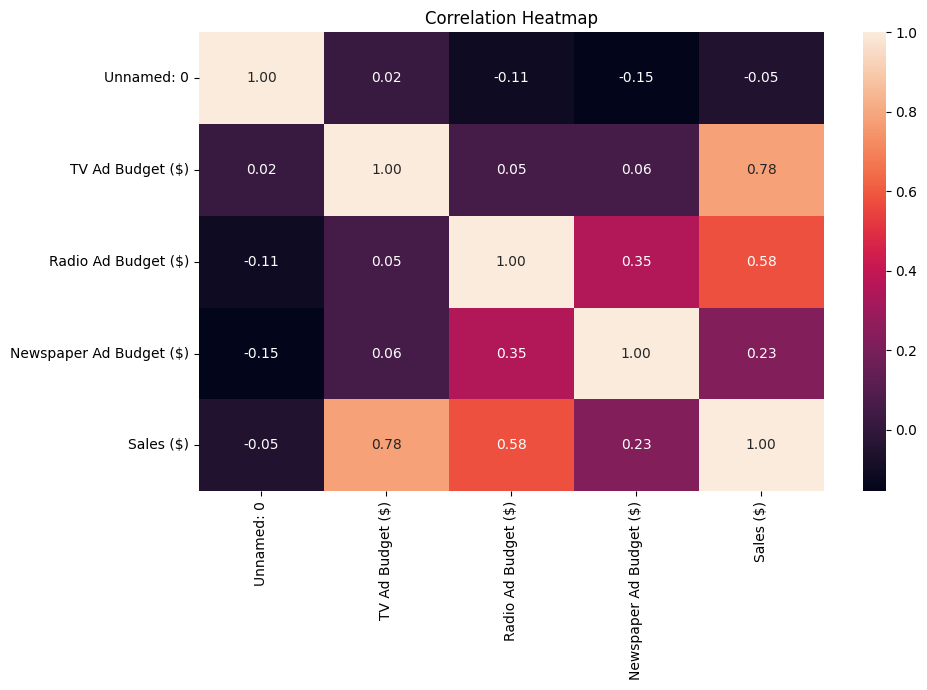

In [ ]:
numeric_df = df.select_dtypes(include=np.number)

if numeric_df.shape[1] >= 2:

    plt.figure(figsize=(10, 7))

    sns.heatmap(
        numeric_df.corr(),
        annot=True,
        fmt=".2f"
    )

    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()

 STEP 13: SALES DISTRIBUTION

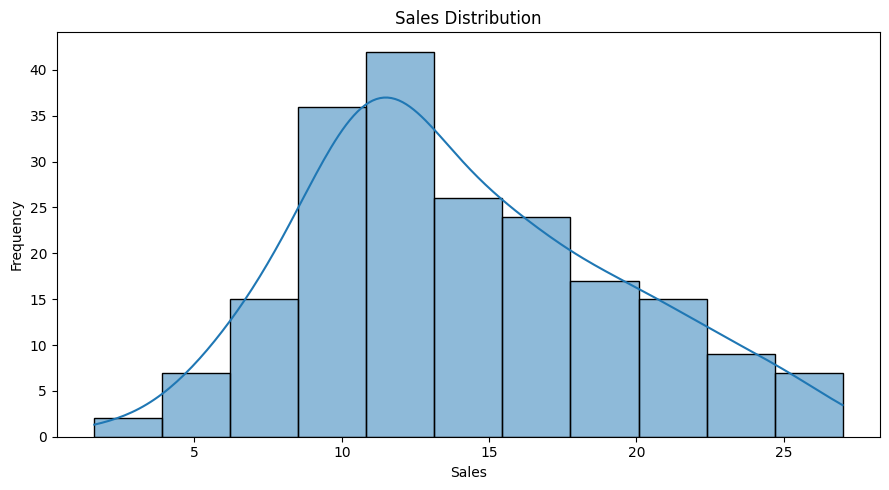

In [ ]:
if sales_col is not None:

    plt.figure(figsize=(9, 5))

    sns.histplot(
        df[sales_col].dropna(),
        kde=True
    )

    plt.title("Sales Distribution")
    plt.xlabel("Sales")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

 STEP 14: SALES VS PROFIT

In [ ]:
if sales_col is not None and profit_col is not None:

    plt.figure(figsize=(9, 6))

    sns.scatterplot(
        data=df,
        x=sales_col,
        y=profit_col
    )

    plt.title("Sales vs Profit")
    plt.xlabel("Sales")
    plt.ylabel("Profit")
    plt.tight_layout()
    plt.show()


STEP 15: MONTHLY SALES TREND

In [ ]:
date_col = None

for column in df.columns:
    if pd.api.types.is_datetime64_any_dtype(df[column]):
        date_col = column
        break

if date_col is not None and sales_col is not None:

    monthly_sales = (
        df.set_index(date_col)
        .resample("ME")[sales_col]
        .sum()
    )

    plt.figure(figsize=(12, 5))

    monthly_sales.plot()

    plt.title("Monthly Sales Trend")
    plt.xlabel("Month")
    plt.ylabel("Sales")
    plt.grid()
    plt.tight_layout()
    plt.show()

STEP 16: TOP BUSINESS RECORDS

In [ ]:
if sales_col is not None:

    top_records = df.nlargest(10, sales_col)

    print("\n========== TOP 10 SALES RECORDS ==========")
    print(top_records[[sales_col]].to_string(index=False))


========== TOP 10 SALES RECORDS ==========
 Sales ($)
      27.0
      26.2
      25.5
      25.4
      25.4
      25.4
      24.7
      24.4
      24.2
      23.8


In [ ]:
print("\n========== BUSINESS INSIGHTS ==========")

if sales_col is not None:
    print("1. Sales performance was analyzed using overall sales and category-wise sales.")

if profit_col is not None:
    print("2. Profitability was analyzed to identify financially strong areas.")

if category_col is not None:
    print("3. Category-level performance was compared to identify important product categories.")

if region_col is not None:
    print("4. Regional performance was analyzed to identify high and low performing regions.")

print("5. Correlation analysis was used to understand relationships between numerical variables.")



========== BUSINESS INSIGHTS ==========
1. Sales performance was analyzed using overall sales and category-wise sales.
5. Correlation analysis was used to understand relationships between numerical variables.


STEP 18: BUSINESS RECOMMENDATIONS

In [ ]:
print("\n========== BUSINESS RECOMMENDATIONS ==========")

print("1. Focus marketing efforts on high-performing categories.")
print("2. Investigate low-performing categories and identify reasons for weak performance.")
print("3. Strengthen strategies in regions showing strong sales and profitability.")
print("4. Analyze low-profit or loss-making transactions for cost optimization.")
print("5. Use sales trends for inventory and resource planning.")


========== BUSINESS RECOMMENDATIONS ==========
1. Focus marketing efforts on high-performing categories.
2. Investigate low-performing categories and identify reasons for weak performance.
3. Strengthen strategies in regions showing strong sales and profitability.
4. Analyze low-profit or loss-making transactions for cost optimization.
5. Use sales trends for inventory and resource planning.


QUESTIONS AND ANSWERS

Q1. What is data storytelling? How is it different from data visualization?

Answer:
Data storytelling combines data analysis, visualization, and narrative to communicate meaningful insights. Data visualization mainly presents information through charts and graphs, while data storytelling also explains the meaning and importance of those findings.

Q2. Why is storytelling important in business analytics and decision-making?

Answer:
Storytelling helps stakeholders understand analytical findings easily. It connects data with business problems and helps communicate insights that can support business decisions.

Q3. What are the essential components of an effective data story?

Answer:
The main components are:

Business problem or objective

Relevant data

Analysis

Meaningful visualizations

Key insights

Recommendations

Clear narrative

Q4. How do Key Performance Indicators (KPIs) enhance business reporting?

Answer:
KPIs provide measurable indicators of business performance. They allow organizations to monitor important metrics such as sales, profit, revenue, growth, and customer performance.

Q5. Why should visualizations be arranged in a logical sequence?

Answer:
A logical sequence helps the audience understand the story step by step. It normally starts with the problem, continues with analysis and findings, and ends with insights and recommendations.

Q6. What factors should be considered while selecting visualizations for a business presentation?

Answer:
The type of data, purpose of analysis, audience, readability, comparison requirements, number of variables, and amount of information should be considered while selecting a visualization.

Q7. Explain how dashboards and storytelling complement each other in Business Intelligence.

Answer:
Dashboards provide an interactive view of important business metrics. Storytelling explains the meaning of those metrics and connects them with business objectives. Together they make analytical information easier to understand and use.

Q8. What challenges may arise while communicating analytical insights to non-technical stakeholders?

Answer:
Common challenges include technical terminology, complex charts, excessive information, unclear explanations, and difficulty connecting analytical results with business objectives.

Q9. Give two real-world examples where data storytelling has influenced business or policy decisions.

Answer:

Retail companies can use sales and customer data to identify high-performing products and adjust inventory and marketing.

Public health organizations can use disease and vaccination data to communicate trends and support public health planning.

Q10. How can effective data storytelling improve strategic planning and organizational performance?

Answer:
Effective data storytelling helps decision-makers understand trends, opportunities, risks, and performance gaps. This can improve resource allocation, planning, monitoring, and evidence-based decision-making.

RESULT

The real-world dataset was successfully analyzed using exploratory data analysis and meaningful visualizations. KPIs, trends, business insights, performance gaps, and actionable recommendations were identified. The complete analysis was presented as a data story to support business decision-making.